<a href="https://colab.research.google.com/github/antoniosolis4536-collab/MIAAD/blob/main/Practica_01_Validacion_Evaluacion_Seleccion_SEM13_274706.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Actividad: Árbol de Decisión con validación cruzada y optimización de hiperparámetros

**Programación para Analítica Descriptiva y Predictiva — MIAAD, UACJ**

**Nombre:** Antonio Ismael Solís Martínez  
**Matrícula:** 274706


## 1. Carga de Bibliotecas, Conjunto de Datos y Análisis Exploratorio de los Datos.

In [1]:
# 1. DECLARACIÓN DE BIBLIOTECAS
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile
import io
import requests

# Configuración de visualización
sns.set_theme(style="whitegrid")

In [5]:
# 2. CARGA DEL CONJUNTO DE DATOS

url_uci = "https://archive.ics.uci.edu/static/public/759/glioma+grading+clinical+and+mutation+features+dataset.zip"

try:
    # Descargar archivo ZIP con reintentos
    for intento in range(3):
        try:
            response = requests.get(url_uci, timeout=60)
            response.raise_for_status()
            break
        except requests.exceptions.RequestException:
            if intento == 2:
                raise
            print(f"Intento {intento + 1} fallido. Reintentando...")

    # Leer archivo CSV del conjunto de datos
    with zipfile.ZipFile(io.BytesIO(response.content)) as z:
        print("Archivos disponibles:", z.namelist())

        with z.open("TCGA_InfoWithGrade.csv") as archivo:
            df = pd.read_csv(archivo)

    # Separar variables predictoras y variable objetivo
    y = df["Grade"]
    X = df.drop("Grade", axis=1)

    print("\nDatos descargados correctamente")
    print("Dimensiones del conjunto de datos:", df.shape)

except requests.exceptions.Timeout:
    print("Error: Tiempo de espera agotado al conectar con UCI.")

except requests.exceptions.RequestException as e:
    print(f"Error de conexión con UCI: {e}")

except Exception as e:
    print(f"Ocurrió un error inesperado: {e}")

Intento 1 fallido. Reintentando...


KeyboardInterrupt: 

## 2. Análisis exploratorio de datos (EDA).

In [ ]:
# 1. FORMA Y ESTRUCTURA DEL CONJUNTO DE DATOS
print("DIMENSIONES DEL CONJUNTO DE DATOS")
print("Registros y variables:", df.shape)

print("\nINFORMACIÓN GENERAL")
df.info()

print("\nESTADÍSTICAS DESCRIPTIVAS")
display(df.describe(include="all"))

DIMENSIONES DEL CONJUNTO DE DATOS
Registros y variables: (839, 24)

INFORMACIÓN GENERAL
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 839 entries, 0 to 838
Data columns (total 24 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Grade             839 non-null    int64  
 1   Gender            839 non-null    int64  
 2   Age_at_diagnosis  839 non-null    float64
 3   Race              839 non-null    int64  
 4   IDH1              839 non-null    int64  
 5   TP53              839 non-null    int64  
 6   ATRX              839 non-null    int64  
 7   PTEN              839 non-null    int64  
 8   EGFR              839 non-null    int64  
 9   CIC               839 non-null    int64  
 10  MUC16             839 non-null    int64  
 11  PIK3CA            839 non-null    int64  
 12  NF1               839 non-null    int64  
 13  PIK3R1            839 non-null    int64  
 14  FUBP1             839 non-null    int64  
 15  RB1

,Grade,Gender,Age_at_diagnosis,Race,IDH1,TP53,ATRX,PTEN,EGFR,CIC,...,FUBP1,RB1,NOTCH1,BCOR,CSMD3,SMARCA4,GRIN2A,IDH2,FAT4,PDGFRA
count,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000,...,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000
mean,0.419547,0.418355,50.935411,0.107271,0.481526,0.414779,0.258641,0.168057,0.133492,0.132300,...,0.053635,0.047676,0.045292,0.034565,0.032181,0.032181,0.032181,0.027414,0.027414,0.026222
std,0.493779,0.493583,15.702339,0.369392,0.499957,0.492978,0.438149,0.374140,0.340309,0.339019,...,0.225431,0.213206,0.208068,0.182784,0.176586,0.176586,0.176586,0.163383,0.163383,0.159889
min,0.000000,0.000000,14.420000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,38.055000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,51.550000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,1.000000,1.000000,62.800000,0.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,1.000000,1.000000,89.290000,3.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000



DISTRIBUCIÓN DE LA VARIABLE OBJETIVO (Grade)
Grade
0    487
1    352
Name: count, dtype: int64

PORCENTAJE POR CLASE
Grade
0    58.05
1    41.95
Name: proportion, dtype: float64


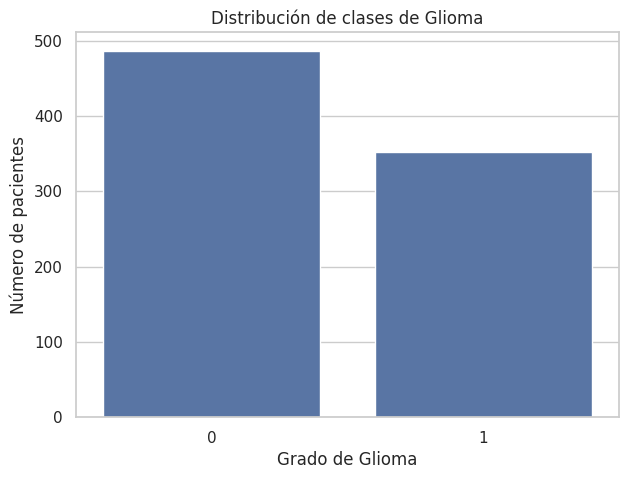

In [ ]:
# 2. DISTRIBUCIÓN DE CLASES
print("\nDISTRIBUCIÓN DE LA VARIABLE OBJETIVO (Grade)")
print(y.value_counts())

print("\nPORCENTAJE POR CLASE")
print((y.value_counts(normalize=True) * 100).round(2))

plt.figure(figsize=(7, 5))
sns.countplot(x=y)
plt.title("Distribución de clases de Glioma")
plt.xlabel("Grado de Glioma")
plt.ylabel("Número de pacientes")
plt.show()


VARIABLES SELECCIONADAS PARA HISTOGRAMAS: ['Gender', 'Age_at_diagnosis', 'Race']


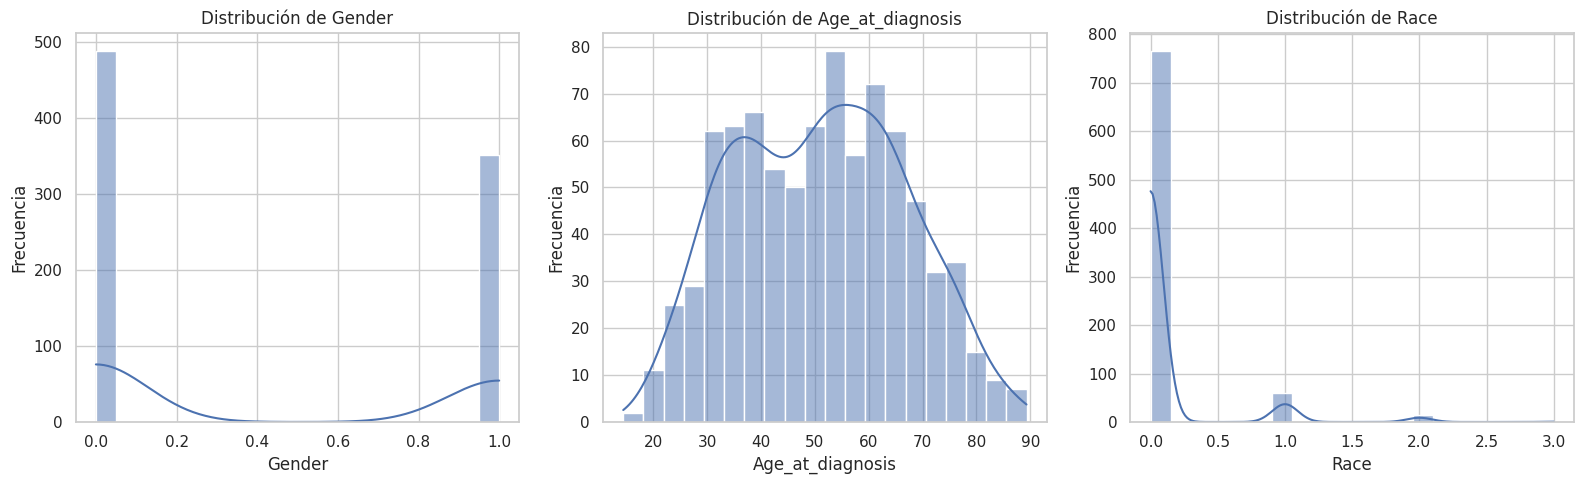

In [ ]:
# 3. HISTOGRAMAS DE VARIABLES NUMÉRICAS
# Identificar variables numéricas
numeric_cols = X.select_dtypes(include=np.number).columns.tolist()

# Seleccionar al menos 3 variables numéricas
# Se prioriza Age si está disponible
hist_cols = []

if "Age" in numeric_cols:
    hist_cols.append("Age")

for col in numeric_cols:
    if col not in hist_cols and len(hist_cols) < 3:
        hist_cols.append(col)

if len(hist_cols) < 3:
    raise ValueError("No se encontraron al menos 3 variables numéricas.")

print("\nVARIABLES SELECCIONADAS PARA HISTOGRAMAS:", hist_cols)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for i, col in enumerate(hist_cols):
    sns.histplot(data=df, x=col, bins=20, kde=True, ax=axes[i])
    axes[i].set_title(f"Distribución de {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Frecuencia")

plt.tight_layout()
plt.show()

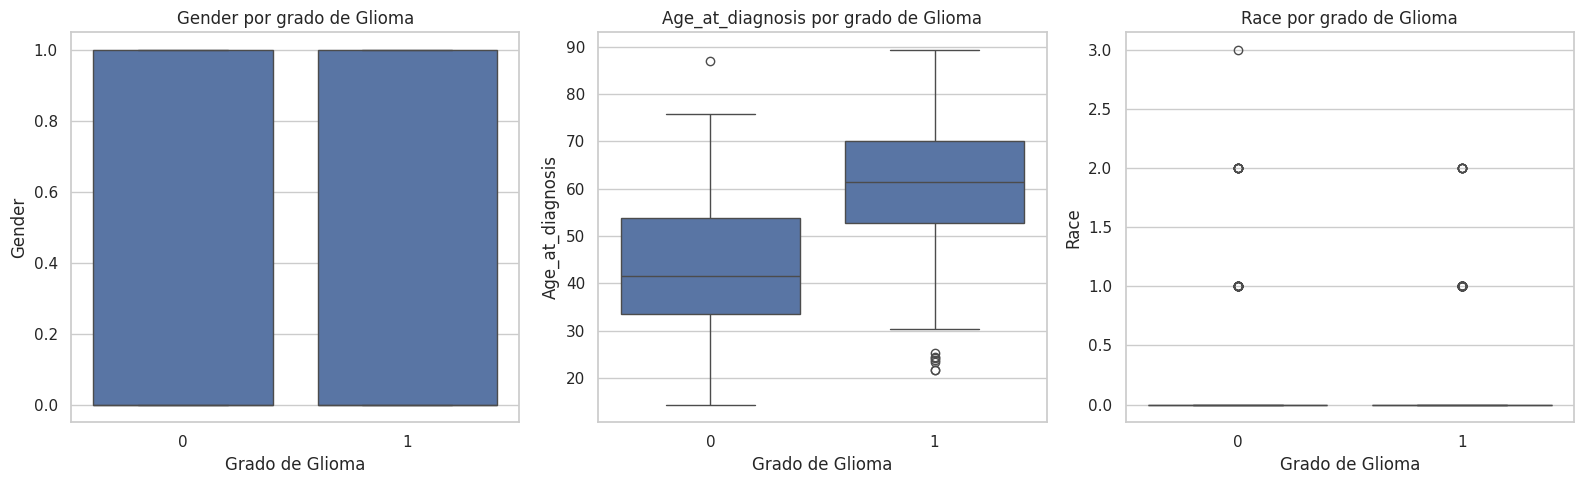

In [ ]:
# 4. BOXPLOTS POR CLASE
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for i, col in enumerate(hist_cols):
    sns.boxplot(data=df, x="Grade", y=col, ax=axes[i])
    axes[i].set_title(f"{col} por grado de Glioma")
    axes[i].set_xlabel("Grado de Glioma")
    axes[i].set_ylabel(col)

plt.tight_layout()
plt.show()

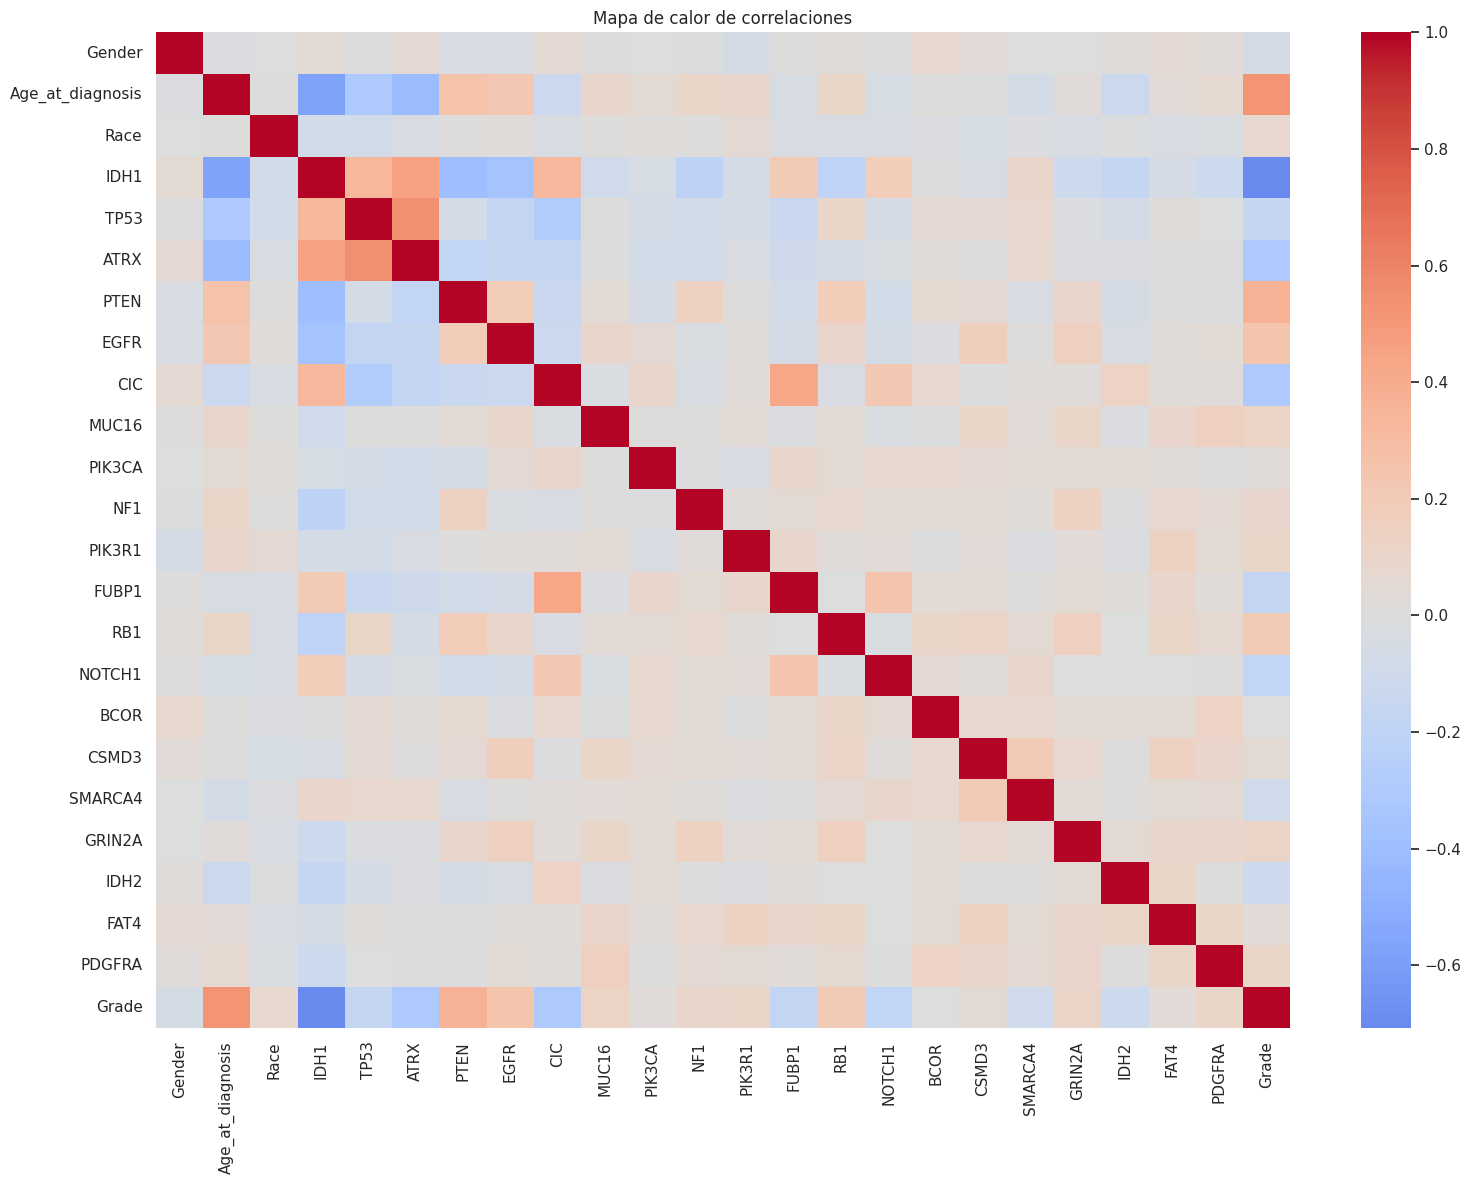

In [ ]:
# 5. MAPA DE CALOR DE CORRELACIONES
# Incluir variables numéricas y la variable objetivo
corr_data = pd.concat(
    [X.select_dtypes(include=np.number), y.rename("Grade")],
    axis=1
)

correlation_matrix = corr_data.corr()

plt.figure(figsize=(16, 12))
sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    annot=False
)
plt.title("Mapa de calor de correlaciones")
plt.tight_layout()
plt.show()

In [ ]:
# 6. IDENTIFICAR ATRIBUTOS CON MAYOR CORRELACIÓN CON GRADE
grade_corr = correlation_matrix["Grade"].drop("Grade")

grade_corr = grade_corr.reindex(
    grade_corr.abs().sort_values(ascending=False).index
)

print("\nATRIBUTOS CON MAYOR CORRELACIÓN CON GRADE")
display(grade_corr.to_frame(name="Correlación con Grade"))


ATRIBUTOS CON MAYOR CORRELACIÓN CON GRADE


,Correlación con Grade
IDH1,-0.708141
Age_at_diagnosis,0.529203
PTEN,0.367174
ATRX,-0.314625
CIC,-0.303459
EGFR,0.241527
RB1,0.195168
NOTCH1,-0.185175
FUBP1,-0.180956
TP53,-0.161786


In [ ]:
# 7. RESUMEN DEL ANÁLISIS
class_counts = y.value_counts()

print("\nRESUMEN DEL ANÁLISIS EXPLORATORIO")

print("\nClases encontradas:")
print(class_counts)

print("\nPorcentaje de cada clase:")
print((y.value_counts(normalize=True) * 100).round(2))

print("\nRelación entre clases:")
print("Clase mayoritaria:", class_counts.idxmax())
print("Clase minoritaria:", class_counts.idxmin())

imbalance_ratio = class_counts.max() / class_counts.min()

print("Relación de desbalance:", round(imbalance_ratio, 2))

if imbalance_ratio > 1.5:
    print("Existe un posible desbalance entre clases.")
else:
    print("Las clases presentan una distribución relativamente equilibrada.")

print("\nAnálisis exploratorio finalizado.")



RESUMEN DEL ANÁLISIS EXPLORATORIO

Clases encontradas:
Grade
0    487
1    352
Name: count, dtype: int64

Porcentaje de cada clase:
Grade
0    58.05
1    41.95
Name: proportion, dtype: float64

Relación entre clases:
Clase mayoritaria: 0
Clase minoritaria: 1
Relación de desbalance: 1.38
Las clases presentan una distribución relativamente equilibrada.

Análisis exploratorio finalizado.


### Reflexiones del análisis exploratorio de datos (EDA)

**1. ¿Existen clases desbalanceadas?**

Al analizar la distribución de la variable objetivo `Grade`, se identificaron 487 registros correspondientes a la clase 0 (58.05%) y 352 registros correspondientes a la clase 1 (41.95%).

Aunque existe una diferencia entre ambas clases, la relación de desbalance es de aproximadamente 1.38, por lo que se considera que el conjunto de datos presenta una distribución relativamente equilibrada. En esta etapa no se considera necesario aplicar técnicas de balanceo, aunque será importante evaluar el desempeño del modelo en ambas clases durante el entrenamiento.

**2. ¿Qué atributos parecen más informativos?**

De acuerdo con la matriz de correlación, los atributos que presentan mayor relación con la variable objetivo `Grade` son:

- **IDH1 (-0.708):** presenta la correlación negativa más alta en valor absoluto.
- **Age_at_diagnosis (0.529):** muestra una relación positiva moderada.
- **PTEN (0.367):** presenta una asociación positiva.
- **ATRX (-0.315) y CIC (-0.303):** muestran asociaciones negativas.

Estos resultados sugieren que dichas variables podrían ser relevantes para la clasificación del grado de Glioma. Sin embargo, será necesario comprobar su importancia mediante modelos de aprendizaje automático.

**Conclusión general**

El análisis exploratorio permitió identificar que el conjunto de datos contiene 839 registros y 24 variables, sin valores faltantes. También se observó que las clases presentan una distribución relativamente equilibrada. Finalmente, se identificaron algunas variables con mayor correlación respecto a la variable objetivo, principalmente IDH1 y Age_at_diagnosis, que podrían aportar información relevante para las siguientes etapas del proyecto.

## 3. Grafica de errores en entrenamiento y prueba arbol de decision con validacion cruzada.

RESULTADOS DE VALIDACIÓN CRUZADA - F1 MACRO


,Profundidad,F1 Macro Entrenamiento,F1 Macro Prueba
0,2,0.8691,0.8678
1,5,0.8867,0.8541
2,10,0.9282,0.8111
3,15,0.9790,0.8018
4,20,0.9958,0.7963
5,25,0.9996,0.7887
6,30,1.0000,0.7899
7,None,1.0000,0.7899


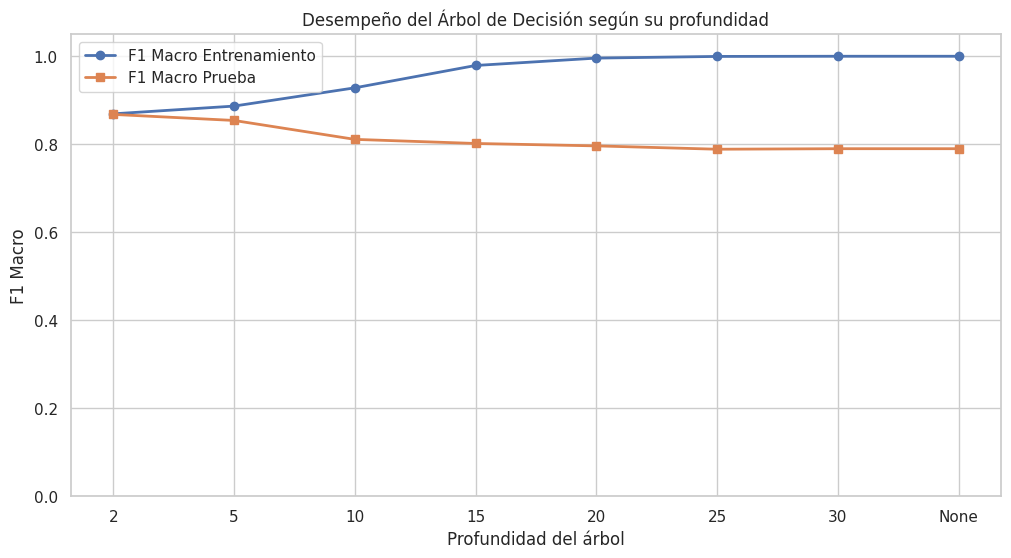


MEJOR RESULTADO
Profundidad: 2
F1 Macro de prueba: 0.8678
F1 Macro de entrenamiento: 0.8691


In [ ]:
# Importar bibliotecas necesarias
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_validate
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. DEFINIR LAS PROFUNDIDADES A EVALUAR
profundidades = [2, 5, 10, 15, 20, 25, 30, None]

# 2. CONFIGURAR STRATIFIED K-FOLD
# Se utilizan 10 particiones y random_state = 7
# Nota: las instrucciones también mencionan random_state = 3.
# Para utilizar ese valor, cambiar 7 por 3.

skf = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=7
)

# Listas para almacenar resultados
resultados = []

# 3. ENTRENAR Y EVALUAR LOS ÁRBOLES DE DECISIÓN
for profundidad in profundidades:

    # Crear modelo de árbol de decisión
    modelo = DecisionTreeClassifier(
        max_depth=profundidad,
        random_state=7
    )

    # Evaluar F1 Macro mediante cross_val_score
    scores_test = cross_val_score(
        modelo,
        X,
        y,
        cv=skf,
        scoring="f1_macro"
    )

    # Obtener resultados de entrenamiento y prueba
    scores_cv = cross_validate(
        modelo,
        X,
        y,
        cv=skf,
        scoring="f1_macro",
        return_train_score=True
    )

    # Calcular promedios
    f1_train = scores_cv["train_score"].mean()
    f1_test = scores_test.mean()

    # Almacenar resultados
    resultados.append({
        "Profundidad": str(profundidad),
        "F1 Macro Entrenamiento": f1_train,
        "F1 Macro Prueba": f1_test
    })

# 4. MOSTRAR TABLA DE RESULTADOS
df_resultados = pd.DataFrame(resultados)

print("RESULTADOS DE VALIDACIÓN CRUZADA - F1 MACRO")
display(df_resultados.round(4))

# 5. GRAFICAR RESULTADOS
plt.figure(figsize=(12, 6))

plt.plot(
    df_resultados["Profundidad"],
    df_resultados["F1 Macro Entrenamiento"],
    marker="o",
    linewidth=2,
    label="F1 Macro Entrenamiento"
)

plt.plot(
    df_resultados["Profundidad"],
    df_resultados["F1 Macro Prueba"],
    marker="s",
    linewidth=2,
    label="F1 Macro Prueba"
)

plt.title("Desempeño del Árbol de Decisión según su profundidad")
plt.xlabel("Profundidad del árbol")
plt.ylabel("F1 Macro")
plt.ylim(0, 1.05)
plt.grid(True)
plt.legend()
plt.show()

# 6. IDENTIFICAR LA MEJOR PROFUNDIDAD
mejor_indice = df_resultados["F1 Macro Prueba"].idxmax()

print("\nMEJOR RESULTADO")
print("Profundidad:", df_resultados.loc[mejor_indice, "Profundidad"])
print("F1 Macro de prueba:",
      round(df_resultados.loc[mejor_indice, "F1 Macro Prueba"], 4))
print("F1 Macro de entrenamiento:",
      round(df_resultados.loc[mejor_indice, "F1 Macro Entrenamiento"], 4))


**Conclusión:**

La profundidad 2 representa la mejor alternativa entre los valores evaluados, ya que proporciona el mayor F1 Macro en prueba y mantiene una diferencia mínima entre entrenamiento y prueba. Por lo tanto, se selecciona esta profundidad como configuración inicial para continuar con el desarrollo del modelo de clasificación.

## 4. Optimización de hiperparámetros con 'RandomizedSearchCV'

In [ ]:

# Importar bibliotecas necesarias
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from scipy.stats import randint

# 1. DEFINIR EL ESPACIO DE BÚSQUEDA
parametros = {
    "criterion": ["gini", "entropy"],
    "max_depth": randint(5, 51),
    "min_samples_split": randint(2, 21)
}

# 2. CONFIGURAR STRATIFIED K-FOLD
skf = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=7
)

# 3. DEFINIR EL MODELO
modelo = DecisionTreeClassifier(random_state=7)

# 4. CONFIGURAR RANDOMIZED SEARCH CV
random_search = RandomizedSearchCV(
    estimator=modelo,
    param_distributions=parametros,
    n_iter=5,
    scoring="f1_macro",
    cv=skf,
    n_jobs=-1,
    random_state=7,
    verbose=1
)

# 5. EJECUTAR LA OPTIMIZACIÓN
random_search.fit(X, y)

# 6. MOSTRAR LOS MEJORES RESULTADOS
print("\nMEJORES HIPERPARÁMETROS ENCONTRADOS:")
print(random_search.best_params_)

print("\nMEJOR RESULTADO (BEST SCORE):")
print(round(random_search.best_score_, 4))

# 7. MOSTRAR RESUMEN DE LAS COMBINACIONES EVALUADAS
resultados_random = pd.DataFrame(random_search.cv_results_)

columnas = [
    "param_criterion",
    "param_max_depth",
    "param_min_samples_split",
    "mean_test_score",
    "std_test_score"
]

print("\nRESUMEN DE LAS COMBINACIONES EVALUADAS:")
display(
    resultados_random[columnas]
    .sort_values(by="mean_test_score", ascending=False)
    .round(4)
)

Fitting 10 folds for each of 5 candidates, totalling 50 fits

MEJORES HIPERPARÁMETROS ENCONTRADOS:
{'criterion': 'entropy', 'max_depth': 9, 'min_samples_split': 5}

MEJOR RESULTADO (BEST SCORE):
0.8505

RESUMEN DE LAS COMBINACIONES EVALUADAS:


,param_criterion,param_max_depth,param_min_samples_split,mean_test_score,std_test_score
0,entropy,9,5,0.8505,0.0337
3,entropy,47,10,0.8220,0.0272
2,gini,19,10,0.8156,0.0517
1,entropy,28,9,0.8154,0.0288
4,entropy,43,6,0.8080,0.0356


**Conclusion**

RandomizedSearchCV encontró como mejor combinación entropy, max_depth=9 y min_samples_split=5, obteniendo un F1 Macro de 0.8505. Sin embargo, este resultado fue inferior al del ejercicio anterior (0.8678), debido posiblemente a que la búsqueda no incluyó la profundidad 2, que había demostrado mejor desempeño.

## 5. Optimización de hiperparámetros con 'GridSearchCV'

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# 1. Definir el espacio de búsqueda
parametros = {
    "criterion": ["gini", "entropy"],
    "max_depth": range(5, 51),
    "min_samples_split": range(2, 21)
}

# 2. Configurar validación cruzada estratificada
skf = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=7
)

# 3. Crear el modelo
modelo = DecisionTreeClassifier(random_state=7)

# 4. Configurar GridSearchCV
grid_search = GridSearchCV(
    estimator=modelo,
    param_grid=parametros,
    scoring="f1_macro",
    cv=skf,
    n_jobs=-1,
    verbose=1
)

# 5. Entrenar y evaluar
grid_search.fit(X, y)

# 6. Imprimir los mejores resultados
print("\nMEJORES HIPERPARÁMETROS ENCONTRADOS:")
print(grid_search.best_params_)

print("\nMEJOR RESULTADO (BEST SCORE):")
print(round(grid_search.best_score_, 4))

Fitting 10 folds for each of 1748 candidates, totalling 17480 fits

MEJORES HIPERPARÁMETROS ENCONTRADOS:
{'criterion': 'entropy', 'max_depth': 5, 'min_samples_split': 13}

MEJOR RESULTADO (BEST SCORE):
0.864


## 6. Optimización de hiperparámetros con RandomizedSearchCV: Accuracy

In [ ]:
import time
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from scipy.stats import randint

# 1. DEFINIR EL ESPACIO DE BÚSQUEDA (el mismo de la sección 4)
parametros_acc = {
    "criterion": ["gini", "entropy"],
    "max_depth": randint(5, 51),             # de 5 a 50
    "min_samples_split": randint(2, 21)      # de 2 a 20
}

# 2. CONFIGURAR STRATIFIED K-FOLD (10 particiones, sin partición previa)
skf_acc = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=7
)

# 3. DEFINIR EL MODELO
modelo_acc = DecisionTreeClassifier(random_state=7)

# 4. CONFIGURAR RANDOMIZED SEARCH CV con accuracy
random_search_acc = RandomizedSearchCV(
    estimator=modelo_acc,
    param_distributions=parametros_acc,
    n_iter=5,
    scoring="accuracy",
    cv=skf_acc,
    n_jobs=-1,
    random_state=7,
    verbose=1
)

# 5. EJECUTAR LA OPTIMIZACIÓN (se mide el tiempo para la reflexión)
inicio = time.time()
random_search_acc.fit(X, y)
tiempo_random_acc = time.time() - inicio

# 6. MOSTRAR LOS MEJORES RESULTADOS
print("\nMEJORES HIPERPARÁMETROS ENCONTRADOS:")
print(random_search_acc.best_params_)

print("\nMEJOR RESULTADO (BEST SCORE, accuracy):")
print(round(random_search_acc.best_score_, 4))

print(f"\nTiempo de ejecución: {tiempo_random_acc:.1f} s")

# 7. RESUMEN DE LAS COMBINACIONES EVALUADAS
resultados_random_acc = pd.DataFrame(random_search_acc.cv_results_)

columnas = [
    "param_criterion",
    "param_max_depth",
    "param_min_samples_split",
    "mean_test_score",
    "std_test_score"
]

print("\nRESUMEN DE LAS COMBINACIONES EVALUADAS:")
display(
    resultados_random_acc[columnas]
    .sort_values(by="mean_test_score", ascending=False)
    .round(4)
)


Fitting 10 folds for each of 5 candidates, totalling 50 fits

MEJORES HIPERPARÁMETROS ENCONTRADOS:
{'criterion': 'entropy', 'max_depth': 9, 'min_samples_split': 5}

MEJOR RESULTADO (BEST SCORE, accuracy):
0.8523

Tiempo de ejecución: 0.2 s

RESUMEN DE LAS COMBINACIONES EVALUADAS:


,param_criterion,param_max_depth,param_min_samples_split,mean_test_score,std_test_score
0,entropy,9,5,0.8523,0.0336
3,entropy,47,10,0.8271,0.0254
2,gini,19,10,0.8224,0.0483
1,entropy,28,9,0.8212,0.0264
4,entropy,43,6,0.8140,0.0339


**Conclusión**

RandomizedSearchCV con accuracy encontró como mejor combinación entropy, max_depth=9 y min_samples_split=5, con un accuracy de 0.8523. Es la misma combinación que obtuvo con F1 Macro en la sección 4 (0.8505), y solo evaluó 5 combinaciones de las 1,748 posibles.

## 7. Optimización de hiperparámetros con GridSearchCV: accuracy

In [ ]:
import time
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Nota: el enunciado de esta sección dice "Métrica de evaluación: f1 Macro", pero el título
# es "accuracy" (y la sección 6 usa accuracy). Se usa scoring="accuracy" para poder
# comparar contra la sección 6.

# 1. DEFINIR EL ESPACIO DE BÚSQUEDA
parametros_grid_acc = {
    "criterion": ["gini", "entropy"],
    "max_depth": range(5, 51),
    "min_samples_split": range(2, 21)
}

# 2. CONFIGURAR VALIDACIÓN CRUZADA ESTRATIFICADA
skf_grid_acc = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=7
)

# 3. CREAR EL MODELO
modelo_grid_acc = DecisionTreeClassifier(random_state=7)

# 4. CONFIGURAR GridSearchCV con accuracy
grid_search_acc = GridSearchCV(
    estimator=modelo_grid_acc,
    param_grid=parametros_grid_acc,
    scoring="accuracy",
    cv=skf_grid_acc,
    n_jobs=-1,
    verbose=1
)

# 5. ENTRENAR Y EVALUAR (se mide el tiempo para la reflexión)
inicio = time.time()
grid_search_acc.fit(X, y)
tiempo_grid_acc = time.time() - inicio

# 6. IMPRIMIR LOS MEJORES RESULTADOS
print("\nMEJORES HIPERPARÁMETROS ENCONTRADOS:")
print(grid_search_acc.best_params_)

print("\nMEJOR RESULTADO (BEST SCORE, accuracy):")
print(round(grid_search_acc.best_score_, 4))

print(f"\nTiempo de ejecución: {tiempo_grid_acc:.1f} s")


Fitting 10 folds for each of 1748 candidates, totalling 17480 fits



MEJORES HIPERPARÁMETROS ENCONTRADOS:
{'criterion': 'entropy', 'max_depth': 5, 'min_samples_split': 13}

MEJOR RESULTADO (BEST SCORE, accuracy):
0.8653

Tiempo de ejecución: 359.3 s


**Conclusión**

GridSearchCV con accuracy encontró como mejor combinación entropy, max_depth=5 y min_samples_split=13, con un accuracy de 0.8653, mejor que el de RandomizedSearchCV (0.8523). Es la misma combinación que con F1 Macro en la sección 5 (0.864). Para esta sección usé accuracy como indica el título, aunque el enunciado dice "f1 Macro" en la métrica.

## 8. Actividad de reflexión y análisis

In [ ]:
# RESUMEN DE LAS CUATRO OPTIMIZACIONES (para responder las preguntas)
busquedas = {
    "Randomized - f1_macro": random_search,
    "Grid - f1_macro": grid_search,
    "Randomized - accuracy": random_search_acc,
    "Grid - accuracy": grid_search_acc,
}

resumen = pd.DataFrame({
    "combinaciones": [len(b.cv_results_["params"]) for b in busquedas.values()],
    "ajustes (x10 folds)": [len(b.cv_results_["params"]) * 10 for b in busquedas.values()],
    "criterion": [b.best_params_["criterion"] for b in busquedas.values()],
    "max_depth": [b.best_params_["max_depth"] for b in busquedas.values()],
    "min_samples_split": [b.best_params_["min_samples_split"] for b in busquedas.values()],
    "best_score": [b.best_score_ for b in busquedas.values()],
}, index=list(busquedas.keys())).round(4)

display(resumen)
print(f"Tiempo Randomized (accuracy): {tiempo_random_acc:.1f} s")
print(f"Tiempo Grid (accuracy): {tiempo_grid_acc:.1f} s")


,combinaciones,ajustes (x10 folds),criterion,max_depth,min_samples_split,best_score
Randomized - f1_macro,5,50,entropy,9,5,0.8505
Grid - f1_macro,1748,17480,entropy,5,13,0.8640
Randomized - accuracy,5,50,entropy,9,5,0.8523
Grid - accuracy,1748,17480,entropy,5,13,0.8653


Tiempo Randomized (accuracy): 0.2 s
Tiempo Grid (accuracy): 359.3 s


**1. ¿Cuál método encontró mejores hiperparámetros?**

GridSearchCV. Su mejor combinación (entropy, max_depth=5, min_samples_split=13) obtuvo 0.8640 en F1 Macro y 0.8653 en accuracy, contra 0.8505 y 0.8523 de RandomizedSearchCV (entropy, max_depth=9, min_samples_split=5). Son alrededor de 1.3 puntos más. Esto es esperable porque Grid revisa todas las combinaciones del espacio y siempre se queda con la mejor de ellas. Aun así, la diferencia es pequeña frente a la variación entre folds (desviación estándar de alrededor de 0.03), así que no es una ventaja enorme.

**2. ¿Cuál fue más costoso computacionalmente?**

GridSearchCV, por mucho. Evaluó 2 × 46 × 19 = 1,748 combinaciones con 10 folds cada una, o sea 17,480 ajustes, contra 50 ajustes de RandomizedSearchCV (350 veces más). En mi ejecución Grid tardó unos 359 segundos (alrededor de 6 minutos) y Randomized menos de 1 segundo (el tiempo exacto cambia según la máquina o Colab, pero la proporción es la misma).

**3. ¿Los resultados en f1_macro fueron distintos en ambos métodos de optimización? ¿Por qué?**

Sí: 0.8505 con Randomized contra 0.8640 con Grid, y con hiperparámetros distintos (max_depth 9 contra 5, min_samples_split 5 contra 13). Randomized solo probó 5 de las 1,748 combinaciones (0.29%), y además casi todas salieron con árboles profundos (9, 47, 19, 28 y 43), que como se vio en la sección 3 sobreajustan. Grid sí incluyó los árboles poco profundos y encontró el mejor.

**4. ¿Los resultados en accuracy fueron distintos en ambos métodos de optimización? ¿Por qué?**

También: 0.8523 con Randomized contra 0.8653 con Grid, por la misma razón: Randomized explora una muestra muy pequeña del espacio y Grid lo explora completo.

**5. ¿Los valores de hiperparámetros fueron iguales en accuracy y F1 Macro?**

Sí. Cada método eligió la misma combinación con las dos métricas: Randomized (entropy, 9, 5) y Grid (entropy, 5, 13). Hay dos motivos: las clases están casi balanceadas (58% y 42%), por lo que accuracy y F1 Macro ordenan las combinaciones de forma muy parecida; y en Randomized se usó el mismo random_state=7, así que se evaluaron las mismas 5 combinaciones y solo cambió la métrica. Lo que cambia es el valor: el accuracy sale un poco más alto que el F1 Macro (0.8653 contra 0.8640 en Grid), porque el F1 Macro promedia el desempeño de ambas clases y penaliza más a la que peor se predice.

**Nota final:** el mejor resultado de todo el ejercicio sigue siendo el de la sección 3 (profundidad 2, F1 Macro de 0.8678), porque ambos espacios de búsqueda empiezan en max_depth=5 y no incluyen árboles tan simples.